# Project 1: Random crop + horizontal flip

Same model, split and optimizer as the baseline (`baseline_colab.ipynb`). The baseline reached about 100% train accuracy but 85.8% local test accuracy, so it overfits. This step tries to close that gap.

**What changed from the baseline:**
1. Training images get a random crop (4-pixel padding) and a random horizontal flip. Validation and test images are untouched.
2. Epochs go from 15 to 30, because augmented data takes longer to converge.

**Before running:** Runtime → Change runtime type → T4 GPU.

## 0. Setup
Put `data.zip` in `MyDrive/dl_proj1/`. It's unzipped to the Colab disk each session, and all outputs are saved back to that Drive folder.

In [1]:
import os, time, zipfile, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import transforms
from google.colab import drive

drive.mount("/content/drive")
OUT_DIR  = "/content/drive/MyDrive/dl_proj1"     # data.zip lives here; outputs saved here
DATA_DIR = "/content/data"
if not os.path.exists(f"{DATA_DIR}/train_labels.csv"):
    shutil.copy(f"{OUT_DIR}/data.zip", "/content/data.zip")
    zipfile.ZipFile("/content/data.zip").extractall(DATA_DIR)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(NO GPU)")

Mounted at /content/drive
torch 2.11.0+cu130 | device: cuda Tesla T4


## 1. Load the images

labeled: (50000, 32, 32, 3) | kaggle test: (2000, 32, 32, 3) | per-class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


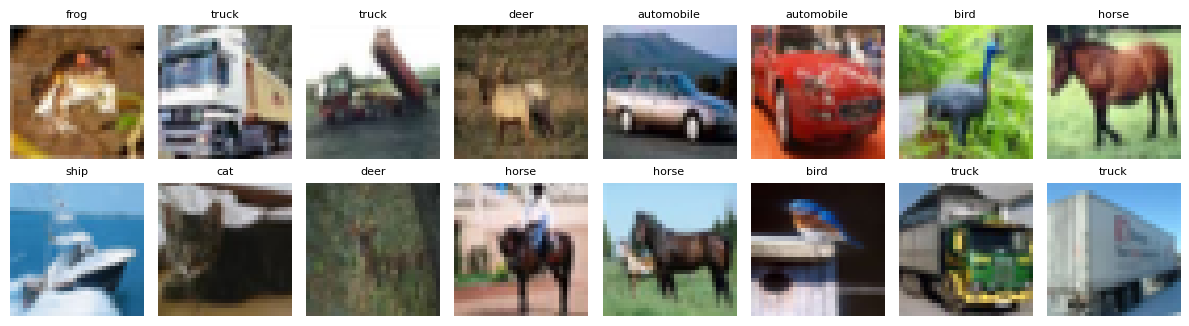

In [2]:
def load_pngs(folder, names):
    return np.stack([np.array(Image.open(f"{folder}/{f}").convert("RGB")) for f in names])

train_df = pd.read_csv(f"{DATA_DIR}/train_labels.csv")
kaggle_test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

cache = f"{OUT_DIR}/cache.npz"               # decoded once (~1 min), then reloaded in seconds
if os.path.exists(cache):
    d = np.load(cache); X_all, y_all, X_kaggle = d["X"], d["y"], d["Xk"]
else:
    X_all    = load_pngs(f"{DATA_DIR}/train_images", train_df.filename)
    y_all    = train_df.label.values.astype(np.int64)
    X_kaggle = load_pngs(f"{DATA_DIR}/test_images", kaggle_test_df.filename)
    np.savez(cache, X=X_all, y=y_all, Xk=X_kaggle)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print("labeled:", X_all.shape, "| kaggle test:", X_kaggle.shape, "| per-class:", np.bincount(y_all))

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(X_all[i]); a.set_title(CLASSES[y_all[i]], fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Config

In [3]:
CONFIG = dict(
    run_name     = "crop_flip",
    seed         = 0,
    channels     = (64, 128, 256),   # C_i: channels per residual layer
    blocks       = (2, 2, 2),        # B_i: residual blocks per residual layer
    epochs       = 30,
    batch_size   = 128,
    lr           = 0.01,             # plain SGD with momentum, constant LR
    momentum     = 0.9,
    val_size     = 5000,
    test_size    = 5000,
)
# Include the settings in the name, so each run keeps its own plot, model and submission file
CONFIG["run_name"] += f"_lr{CONFIG['lr']}_ep{CONFIG['epochs']}_bs{CONFIG['batch_size']}"
torch.manual_seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])

## 3. Train / validation / local-test split, with augmentation
The split is the same as the baseline, so results are directly comparable. Only the training set is augmented, with a new random crop and flip each time an image is drawn. Crop and flip follow the standard CIFAR-10 recipe from [kuangliu/pytorch-cifar](https://github.com/kuangliu/pytorch-cifar).

In [4]:
rng = np.random.default_rng(CONFIG["seed"])
val_idx, test_idx, tr_idx = [], [], []
per_val, per_test = CONFIG["val_size"] // 10, CONFIG["test_size"] // 10
for c in range(10):
    idx = rng.permutation(np.where(y_all == c)[0])
    val_idx += list(idx[:per_val]); test_idx += list(idx[per_val:per_val + per_test]); tr_idx += list(idx[per_val + per_test:])

def to_tensor(x): return torch.tensor(x).permute(0, 3, 1, 2).float() / 255     # NHWC uint8 -> NCHW float

X_tr = to_tensor(X_all[tr_idx])
MEAN, STD = X_tr.mean((0, 2, 3), keepdim=True), X_tr.std((0, 2, 3), keepdim=True)
def prep(x): return (to_tensor(x) - MEAN) / STD

def make_loader(idx, shuffle):
    return DataLoader(TensorDataset(prep(X_all[idx]), torch.tensor(y_all[idx])),
                      batch_size=CONFIG["batch_size"], shuffle=shuffle, pin_memory=(device == "cuda"))

train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist()),
])

class AugmentedTrainSet(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

train_loader = DataLoader(AugmentedTrainSet(X_all[tr_idx], y_all[tr_idx], train_tf), batch_size=CONFIG["batch_size"],
                          shuffle=True, num_workers=2, persistent_workers=True, pin_memory=(device == "cuda"))
val_loader   = make_loader(val_idx, shuffle=False)
test_loader  = make_loader(test_idx, shuffle=False)
del X_tr
print(f"train {len(tr_idx)} | val {len(val_idx)} | local test {len(test_idx)}")
print("mean", MEAN.flatten().numpy().round(4), "std", STD.flatten().numpy().round(4))

train 40000 | val 5000 | local test 5000
mean [0.4913 0.4821 0.4466] std [0.2471 0.2436 0.2616]


## 4. Model
A residual block computes `ReLU(S(x) + F(x))`, where F = conv3×3 → BN → ReLU → conv3×3 → BN.
S is the identity, or a 1×1 conv + BN when the stride or channel count changes.

The baseline is ResNet-18 with its last 512-channel layer removed: 3 residual layers with 2 blocks each and 64/128/256 channels, then global average pooling and an FC layer.
The full ResNet-18 has 11.2M params, which is over the 5M limit.

In [5]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Sequential()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, channels, blocks, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False), nn.BatchNorm2d(channels[0]), nn.ReLU())
        layers, cin = [], channels[0]
        for i, (c, b) in enumerate(zip(channels, blocks)):
            for j in range(b):
                layers.append(BasicBlock(cin, c, stride=2 if (i > 0 and j == 0) else 1))   # downsample at start of layers 2, 3, ...
                cin = c
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, num_classes)

    def forward(self, x):
        x = self.layers(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

model = ResNet(CONFIG["channels"], CONFIG["blocks"]).to(device)
n_params = count_params(model)
print(model)
print(f"\nTrainable parameters: {n_params:,}")
assert n_params <= 5_000_000, "Over the 5M parameter limit!"

ResNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (layers): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNor

## 5. Train

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=CONFIG["lr"], momentum=CONFIG["momentum"])

def run_epoch(loader, train):
    model.train(train); total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            out = model(xb); loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return total_loss / n, correct / n

hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
t0 = time.time()
for ep in range(CONFIG["epochs"]):
    tl, ta = run_epoch(train_loader, train=True)
    vl, va = run_epoch(val_loader, train=False)
    for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
    print(f"epoch {ep+1:2d}/{CONFIG['epochs']} | train loss {tl:.3f} acc {ta*100:5.2f}% | val loss {vl:.3f} acc {va*100:5.2f}% | {time.time()-t0:4.0f}s")
train_minutes = (time.time() - t0) / 60

epoch  1/30 | train loss 1.467 acc 46.13% | val loss 1.186 acc 57.64% |   35s
epoch  2/30 | train loss 1.008 acc 63.81% | val loss 1.139 acc 62.10% |   69s
epoch  3/30 | train loss 0.789 acc 72.12% | val loss 1.007 acc 67.96% |  105s
epoch  4/30 | train loss 0.663 acc 76.94% | val loss 0.846 acc 72.12% |  144s
epoch  5/30 | train loss 0.581 acc 79.81% | val loss 0.902 acc 72.58% |  180s
epoch  6/30 | train loss 0.523 acc 81.91% | val loss 0.590 acc 80.04% |  218s
epoch  7/30 | train loss 0.473 acc 83.53% | val loss 0.564 acc 81.36% |  255s
epoch  8/30 | train loss 0.434 acc 85.02% | val loss 0.682 acc 77.36% |  292s
epoch  9/30 | train loss 0.404 acc 85.97% | val loss 0.677 acc 79.14% |  330s
epoch 10/30 | train loss 0.369 acc 87.13% | val loss 0.602 acc 81.48% |  367s
epoch 11/30 | train loss 0.350 acc 87.91% | val loss 0.553 acc 83.26% |  404s
epoch 12/30 | train loss 0.327 acc 88.64% | val loss 0.537 acc 83.08% |  442s
epoch 13/30 | train loss 0.305 acc 89.09% | val loss 0.566 acc 8

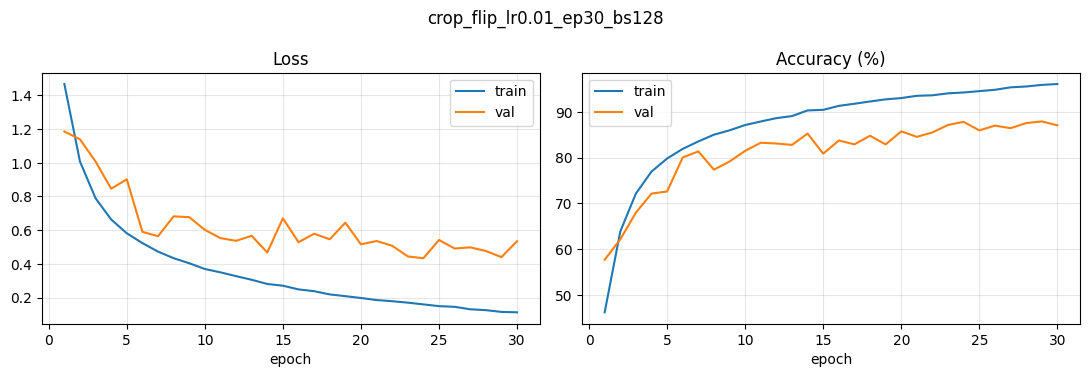

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
epochs = range(1, CONFIG["epochs"] + 1)
ax[0].plot(epochs, hist["train_loss"], label="train"); ax[0].plot(epochs, hist["val_loss"], label="val"); ax[0].set_title("Loss")
ax[1].plot(epochs, [a*100 for a in hist["train_acc"]], label="train"); ax[1].plot(epochs, [a*100 for a in hist["val_acc"]], label="val"); ax[1].set_title("Accuracy (%)")
for a in ax: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.suptitle(CONFIG["run_name"]); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves_{CONFIG['run_name']}.png", dpi=120); plt.show()

## 6. Final accuracy on the held-out local test split

In [8]:
test_loss, test_acc = run_epoch(test_loader, train=False)

print("=" * 50)
print(f"Run:                  {CONFIG['run_name']}")
print(f"Trainable parameters: {n_params:,}")
print(f"Train accuracy:       {hist['train_acc'][-1]*100:.2f}%")
print(f"Validation accuracy:  {hist['val_acc'][-1]*100:.2f}%")
print(f"Local test accuracy:  {test_acc*100:.2f}%")
print(f"Training time:        {train_minutes:.1f} min")
print("=" * 50)

# per-class accuracy on the local test split
model.eval(); preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(model(xb.to(device)).argmax(1).cpu()); labels.append(yb)
preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
print(pd.Series({CLASSES[c]: f"{(preds[labels == c] == c).mean()*100:.1f}%" for c in range(10)}, name="per-class test acc").to_string())

Run:                  crop_flip_lr0.01_ep30_bs128
Trainable parameters: 2,777,674
Train accuracy:       96.11%
Validation accuracy:  87.06%
Local test accuracy:  87.46%
Training time:        18.5 min
airplane      82.2%
automobile    96.0%
bird          92.0%
cat           80.2%
deer          91.2%
dog           68.0%
frog          91.0%
horse         86.8%
ship          93.2%
truck         94.0%


## 7. Log the run and save outputs
Each run appends one row to `experiments.csv`. That table tracks progress and becomes the results table in the report.
The model weights and `submission_<run_name>.csv` are saved too. To submit, download the CSV and upload it with Submit Prediction on Kaggle, and only when the local test accuracy clearly improves.

In [9]:
torch.save(model.state_dict(), f"{OUT_DIR}/model_{CONFIG['run_name']}.pt")

log_path = f"{OUT_DIR}/experiments.csv"
row = {"run_name": CONFIG["run_name"], "params": n_params, "epochs": CONFIG["epochs"],
       "val_acc": round(hist["val_acc"][-1], 4), "local_test_acc": round(test_acc, 4),
       "minutes": round(train_minutes, 1), "config": str(CONFIG), "kaggle_acc": ""}
pd.DataFrame([row]).to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
print(pd.read_csv(log_path)[["run_name", "params", "val_acc", "local_test_acc", "minutes", "kaggle_acc"]].to_string(index=False))

# Kaggle submission file (only upload it when it's worth one of the daily submissions)
X_k = prep(X_kaggle); kaggle_preds = []
model.eval()
with torch.no_grad():
    for k in range(0, len(X_k), 500):
        kaggle_preds.append(model(X_k[k:k+500].to(device)).argmax(1).cpu())
sub = pd.DataFrame({"id": kaggle_test_df.id, "label": torch.cat(kaggle_preds).numpy()})
sub_path = f"{OUT_DIR}/submission_{CONFIG['run_name']}.csv"
sub.to_csv(sub_path, index=False)
print(f"\nSaved {sub_path}  ({len(sub)} rows, predicted class counts {np.bincount(sub.label, minlength=10)})")

                   run_name  params  val_acc  local_test_acc  minutes  kaggle_acc
             step1_baseline 2777674   0.8450          0.8580      9.5         NaN
crop_flip_lr0.01_ep30_bs128 2777674   0.8706          0.8746     18.5         NaN

Saved /content/drive/MyDrive/dl_proj1/submission_crop_flip_lr0.01_ep30_bs128.csv  (2000 rows, predicted class counts [123 224 297 218 218 152 180 186 206 196])
